### Multi Agent Suprvisor With RAG
Supervisor is a multi-agent architecture where specialized agents are coordinated by a central supervisor agent. The supervisor agent controls all communication flow and task delegation, making decisions about which agent to invoke based on the current context and task requirements.

In this tutorial, you will build a supervisor system with two agents — a research and a math expert. By the end of the tutorial you will:

1. Build specialized research and math agents
2. Build a supervisor for orchestrating them with the prebuilt langgraph-supervisor
3. Build a supervisor 
4. Implement advanced task delegation


In [1]:
import os
from dotenv import load_dotenv
load_dotenv()

from langchain_groq import ChatGroq
os.environ["TAVILY_API_KEY"]=os.getenv("TAVILY_API_KEY")
os.environ["GROQ_API_KEY"] = os.getenv("GROQ_API_KEY")

In [2]:
llm = ChatGroq(
    model="openai/gpt-oss-120b",
    temperature=0
)
llm

ChatGroq(metadata={'lc_versions': {'langchain-core': '1.7.0', 'langchain': '1.4.7'}}, profile={'name': 'GPT OSS 120B', 'release_date': '2025-08-05', 'last_updated': '2026-05-27', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': False, 'temperature': True}, client=<groq.resources.chat.completions.Completions object at 0x00000272FE2674D0>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x00000272FE4002F0>, model_name='openai/gpt-oss-120b', temperature=1e-08, model_kwargs={}, groq_api_key=SecretStr('**********'))

In [3]:

from typing import Annotated

from langchain_tavily import TavilySearch
from langchain_core.tools import tool

from langchain_community.tools import WikipediaQueryRun
from langchain_community.utilities import WikipediaAPIWrapper
from langchain_community.document_loaders import TextLoader
from langchain_community.vectorstores import FAISS

from langchain_huggingface import HuggingFaceEmbeddings
from langchain_text_splitters import RecursiveCharacterTextSplitter


C:\Users\aadit\AppData\Local\Temp\ipykernel_5424\2425968528.py:6: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.tools import WikipediaQueryRun


In [4]:
tavily_tool=TavilySearch(max_results=5)

In [5]:
embedding= HuggingFaceEmbeddings(
    model_name ="sentence-transformers/all-MiniLM-L6-v2"
)
embedding = embedding

d:\Mission Project\AgenticAI\agc\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 103/103 [00:00<00:00, 5083.41it/s]


In [6]:
## Generic function to create a retrieval tool
from langchain_core.tools import Tool

def make_retriever_tool_from_text(file,name,desc):
    docs = TextLoader(file,encoding="utf-8").load()
    chunks = RecursiveCharacterTextSplitter(chunk_size=500, chunk_overlap=50).split_documents(docs)
    vs = FAISS.from_documents(chunks, embedding)
    retriever = vs.as_retriever()

    def tool_func(query:str)-> str:
        print(f" Using tool: {name}")
        results = retriever.invoke(query)
        return "\n\n".join(doc.page_content for doc in results)

    return Tool(name=name, description=desc,func=tool_func)

internal_tool_1 = make_retriever_tool_from_text("research_notes.txt",
                                                "InernalResearchNotes",
                                                "Search internal research notes for experimental results" )

internal_tool_1

Tool(name='InernalResearchNotes', description='Search internal research notes for experimental results', func=<function make_retriever_tool_from_text.<locals>.tool_func at 0x00000272BEEB36A0>)

In [7]:
from langchain_tavily import TavilySearch

web_search = TavilySearch(max_results=3)
web_search

TavilySearch(max_results=3, api_wrapper=TavilySearchAPIWrapper(tavily_api_key=SecretStr('**********'), api_base_url=None))

C:\Users\aadit\AppData\Local\Temp\ipykernel_5424\908600646.py:3: LangGraphDeprecatedSinceV10: create_react_agent has been moved to `langchain.agents`. Please update your import to `from langchain.agents import create_agent`. Deprecated in LangGraph V1.0 to be removed in V2.0.
  research_agent = create_react_agent(


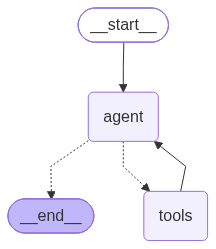

In [8]:
from langgraph.prebuilt import create_react_agent

research_agent = create_react_agent(
    model=llm,
    tools=[web_search, internal_tool_1],
    prompt=(
        "You are a research agent.\n\n"
        "INSTRUCTIONS: \n"
        "- Assist ONLY with researach-related tasks, DO NOT do any math\n"
        "- After you're done with your tasks, respond to the supervisor directly\n"
        "- Respond ONLY with the results of your work, do NOT include ANY other text."
    ),
    name = "research_agent"
)
research_agent

In [9]:
def add(a: float, b:float):
    """Add two numbers."""
    return a+b

def multiply(a: float, b: float):
    """Multiply two numbers."""
    return a*b

def divide(a:float, b:float):
    """Divide two numbers."""
    return a/b

math_agent = create_react_agent(
    model=llm,
    tools=[add,multiply,divide],
    prompt=(
        "You are a maath agent. \n\n"
        "INSTRUCTIONS: \n"
        "- Assist ONLY with math-related tasks\n"
        "- After you're done with your tasks, respond to the supervisor directly\n"
        "- Respond ONLY with the results of your work, do NOT include ANY other text."

    ),
    name = "math_agent"
)

C:\Users\aadit\AppData\Local\Temp\ipykernel_5424\848544077.py:13: LangGraphDeprecatedSinceV10: create_react_agent has been moved to `langchain.agents`. Please update your import to `from langchain.agents import create_agent`. Deprecated in LangGraph V1.0 to be removed in V2.0.
  math_agent = create_react_agent(


In [11]:
!UV pip install langgraph-supervisor

Using Python 3.13.15 environment at: D:\Mission Project\AgenticAI\agc
Resolved 39 packages in 1.67s
Prepared 1 package in 387ms
         If the cache and target directories are on different filesystems, hardlinking may not be supported.
         If this is intentional, set `export UV_LINK_MODE=copy` or use `--link-mode=copy` to suppress this warning.
Installed 1 package in 13ms
 + langgraph-supervisor==0.0.31


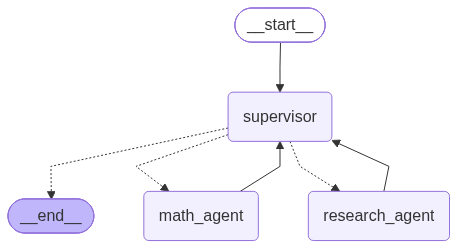

In [13]:
## create supervisor agent
from langgraph_supervisor import create_supervisor

supervisor= create_supervisor(
    model = llm,
    agents = [research_agent,math_agent],
    prompt =(
        "You are a supervisor managing two agents:\n"
        "- a research agent. Assign research-related tasks to this agent\n"
        "- a math agent. Assign math-related tasks to this agent\n"
        "Assign work to one agent at a time, do not call agents in parallel. \n"
        "Do not do any work yourself."
    ),
    add_handoff_back_messages = True,
    output_mode = "full_history"
).compile()

supervisor

In [17]:
response=supervisor.invoke({"messages":" list one transformer variants in production deployments from the retriever and then tell me what is 5 plus 10"})


In [18]:
response

{'messages': [HumanMessage(content=' list one transformer variants in production deployments from the retriever and then tell me what is 5 plus 10', additional_kwargs={}, response_metadata={}, id='22a97280-9942-42b2-9cc4-9304eb368a13'),
  AIMessage(content='', additional_kwargs={'reasoning_content': 'We need to assign tasks: first research: list one transformer variant in production deployments from the retriever. Then math: compute 5+10. Must do one at a time. So first call research_agent.', 'tool_calls': [{'id': 'fc_8113da6d-e3de-4ddc-97f4-cc46120a6580', 'function': {'arguments': '{"task":"list one transformer variant in production deployments from the retriever"}', 'name': 'transfer_to_research_agent'}, 'type': 'function'}]}, response_metadata={'token_usage': {'completion_tokens': 84, 'prompt_tokens': 226, 'total_tokens': 310, 'completion_time': 0.177922789, 'completion_tokens_details': {'reasoning_tokens': 44}, 'prompt_time': 0.042639566, 'prompt_tokens_details': None, 'queue_time'

In [19]:
response["messages"][-1].content

'Here’s the combined response:\n\n- **Transformer variant in production:** **DeiT (Data‑efficient Image Transformer)**\n- **5\u202f+\u202f10 = 15**'